# House Price Prediction ML Project

**Project Problem Statement**

`Objective`

To build an accurate machine learning pipeline that predicts house price using structural, temporal, and spatial features.

`Core Challenges`

* Skewed Data: Extreme luxury house prices skew the target variable and confuse basic models.
* Mixed Layouts: Features contain both highly skewed continuous numbers (sqft_living, yr_built) and text categories (Condition_Label).
* Feature Noise: Redundant metrics can slow down training and cause overfitting.

`The Solution`
* Clean outliers using IQR, 
* normalize skewed data via Log/Power transforms, 
* automate processing with Pipelines to prevent data leakage

**Step 1: Import Libraries**

In [2]:
# System and Data manipulation
import joblib

# Visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor

# feature selection
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer

# Regression Models
from sklearn.linear_model import LinearRegression

# Regression Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Preprocessing & Selection
from sklearn.model_selection import (
    RandomizedSearchCV,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor


**Step 2: Load Dataset**

In [3]:
df = pd.read_csv('kc_house_data.csv')

**Step 3: Understand Your Data (EDA)**

In [4]:
print("\n[First 5 Rows]:\n", df.head())


[First 5 Rows]:
            id             date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520  20141013T000000  221900.0         3       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400   
2     10000     1.0           0     0  ...      6         770              0   
3      5000     1.0           0     0  ...      7        1050            910   
4      8080     1.0           0     0  ...      8        1680              0   

   yr_built  yr_renovated  zipco

In [5]:
print(f"\n[Shape of Dataset]: {df.shape}")


[Shape of Dataset]: (21613, 21)


In [6]:
print("\n[Info Structural Check]:")
df.info()


[Info Structural Check]:
<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  floa

In [7]:
print("\n[Data Types]:\n", df.dtypes)


[Data Types]:
 id                 int64
date                 str
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object


In [8]:
print("\n[Descriptive Statistics]:\n", df.describe().T)


[Descriptive Statistics]:
                  count          mean           std           min  \
id             21613.0  4.580302e+09  2.876566e+09  1.000102e+06   
price          21613.0  5.400881e+05  3.671272e+05  7.500000e+04   
bedrooms       21613.0  3.370842e+00  9.300618e-01  0.000000e+00   
bathrooms      21613.0  2.114757e+00  7.701632e-01  0.000000e+00   
sqft_living    21613.0  2.079900e+03  9.184409e+02  2.900000e+02   
sqft_lot       21613.0  1.510697e+04  4.142051e+04  5.200000e+02   
floors         21613.0  1.494309e+00  5.399889e-01  1.000000e+00   
waterfront     21613.0  7.541757e-03  8.651720e-02  0.000000e+00   
view           21613.0  2.343034e-01  7.663176e-01  0.000000e+00   
condition      21613.0  3.409430e+00  6.507430e-01  1.000000e+00   
grade          21613.0  7.656873e+00  1.175459e+00  1.000000e+00   
sqft_above     21613.0  1.788391e+03  8.280910e+02  2.900000e+02   
sqft_basement  21613.0  2.915090e+02  4.425750e+02  0.000000e+00   
yr_built       21613

In [9]:
# Target Variable Analysis (Price)
print(f"\n[Target Skewness Before Transformation]: {df['price'].skew():.2f}")


[Target Skewness Before Transformation]: 4.02


**Step 4: Data Cleaning**

In [10]:
# 1. Remove Duplicates
print(f"Duplicates found: {df.duplicated().sum()}")
df = df.drop_duplicates()

Duplicates found: 0


In [11]:
# 2. Remove Unwanted Columns
df.drop("id", axis=1, inplace=True)

In [12]:
# 3. Handle Missing Values
missing_values = df.isnull().sum()
print("Missing values per column:\n", missing_values[missing_values > 0])
# (Note: We will handle actual imputation later in our Step 9 Preprocessing Pipeline!)

Missing values per column:
 Series([], dtype: int64)


In [13]:
# 4. Fix Data Types
df['date'] = pd.to_datetime(df['date'], format='%Y%m%dT%H%M%S', errors='coerce')
df['year_sold'] = df['date'].dt.year.fillna(2015).astype(int)

In [14]:
# 5. Outlier Detection and Capping
print("--- CLEANING OUTLIERS ACROSS ALL COLUMNS (IQR METHOD) ---")

# Exclude 'price' if you are already using np.log1p on it (log handles its outliers)
num_cols_for_outliers = df.select_dtypes(include=[np.number]).columns.tolist()
if 'price' in num_cols_for_outliers:
    num_cols_for_outliers.remove('price')

initial_rows = len(df)

for col in num_cols_for_outliers:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

print("Outlier removal complete.")
print(f"Removed {initial_rows - len(df)} total rows across all columns.")
print(f"Remaining dataset shape: {df.shape}")


--- CLEANING OUTLIERS ACROSS ALL COLUMNS (IQR METHOD) ---


Outlier removal complete.
Removed 7641 total rows across all columns.
Remaining dataset shape: (13972, 21)


**Step 5: Feature Engineering**

In [15]:
# Create logical domain features
df['HouseAge'] = np.clip(df['year_sold'] - df['yr_built'], 0, None)
df['IsRenovated'] = (df['yr_renovated'] > 0).astype(int)
df['BedBathRatio'] = df['bathrooms'] / (df['bedrooms'] + 1)
df['LivingLotRatio'] = df['sqft_living'] / (df['sqft_lot'] + 1)

# Create a true categorical text feature for pipeline demonstration purposes
df['Condition_Label'] = df['condition'].map({1:'Poor', 2:'Fair', 3:'Average', 4:'Good', 5:'Luxury'}).fillna('Average')

# Drop remaining raw columns that are no longer needed
df = df.drop(columns=['date', 'zipcode', 'condition'])

**Step 6: Data Visualization**

Univariate:

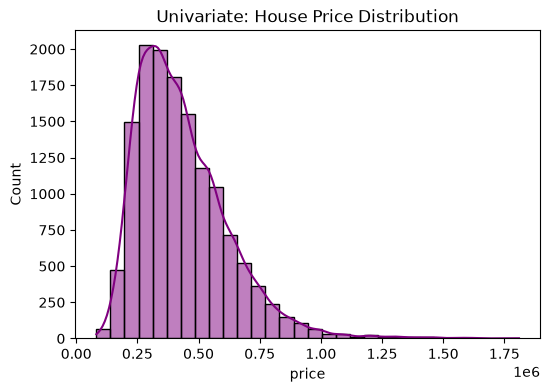

In [16]:
# 1. Univariate: Histogram (Target variable distribution)
plt.figure(figsize=(6, 4))
sns.histplot(df['price'], kde=True, bins=30, color='purple')
plt.title('Univariate: House Price Distribution')
plt.show()

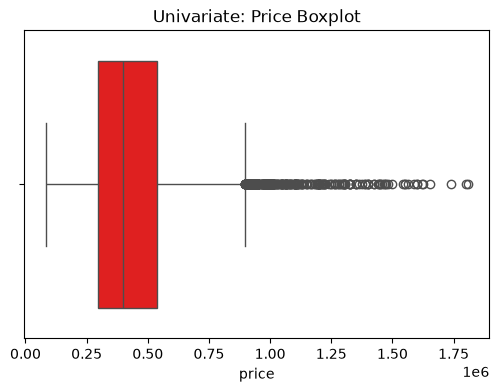

In [17]:
# 2. Univariate: Boxplot (Check for outliers visually)
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['price'], color='red')
plt.title('Univariate: Price Boxplot')
plt.show()

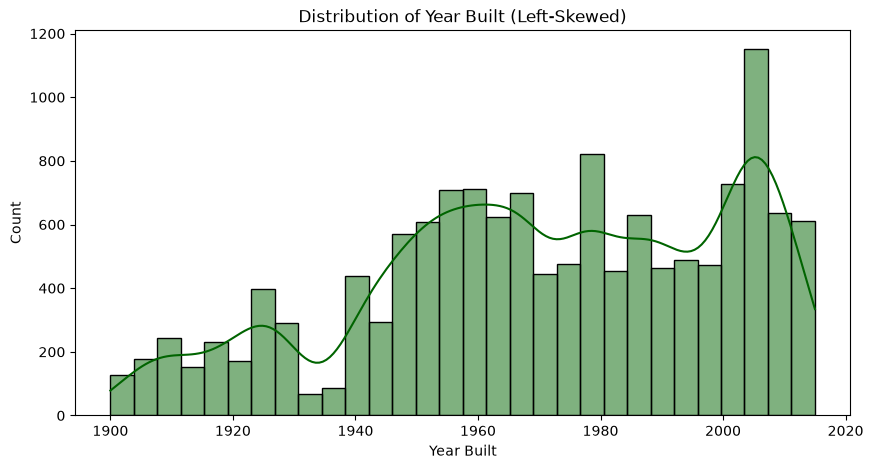

In [18]:
# 3. 
plt.figure(figsize=(10, 5))
sns.histplot(df['yr_built'], kde=True, color='darkgreen', bins=30)
plt.title('Distribution of Year Built (Left-Skewed)')
plt.xlabel('Year Built')
plt.ylabel('Count')
plt.show()

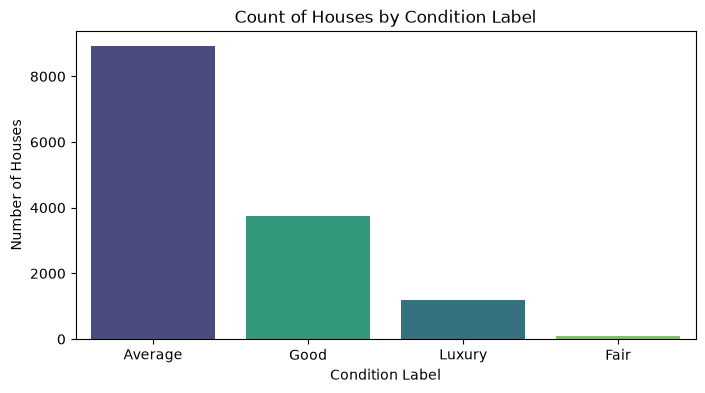

In [19]:
#4.
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Condition_Label', palette='viridis', hue='Condition_Label', legend=False,order=df['Condition_Label'].value_counts().index)
plt.title('Count of Houses by Condition Label')
plt.xlabel('Condition Label')
plt.ylabel('Number of Houses')
plt.show()

Bivariate:

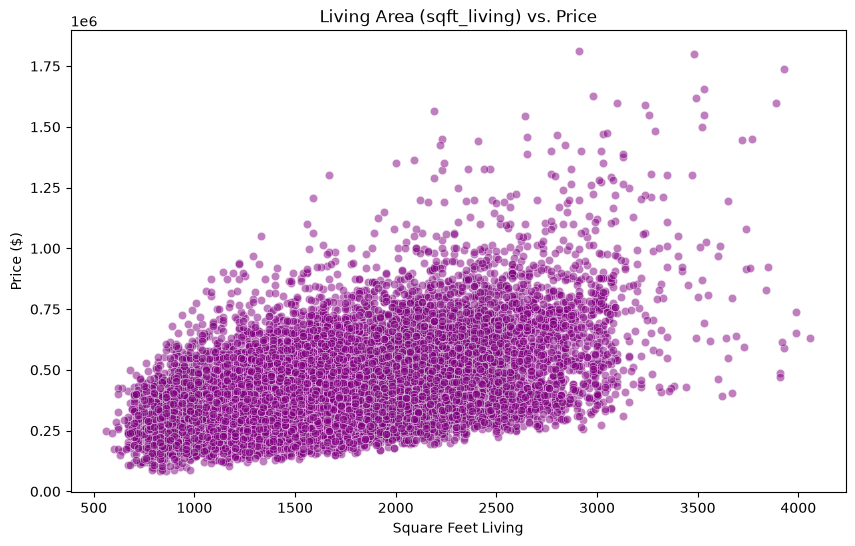

In [20]:
# 2a. Numerical Feature vs. Target (Bivariate Scatter Plot)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='sqft_living', y='price', alpha=0.5, color='purple')
plt.title('Living Area (sqft_living) vs. Price')
plt.xlabel('Square Feet Living')
plt.ylabel('Price ($)')
plt.show()

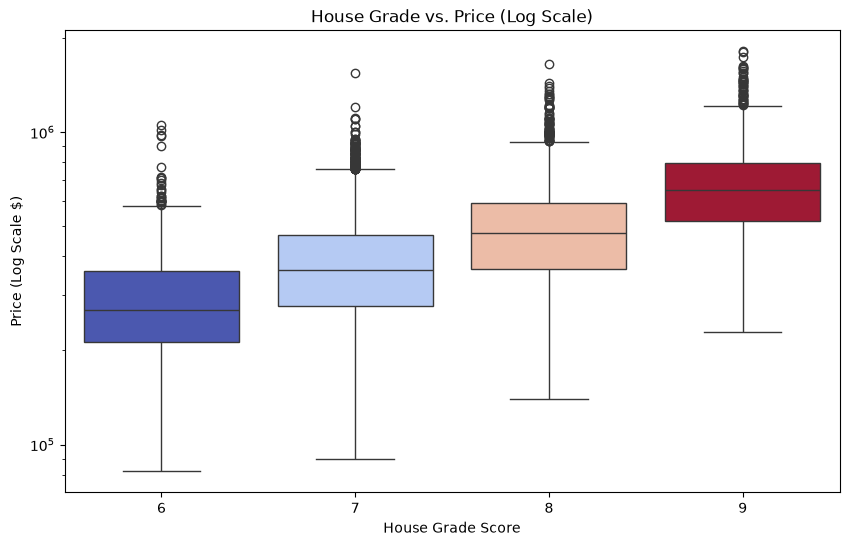

In [21]:
# 2b. Categorical Feature vs. Target (Bivariate Box Plot)
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='grade', y='price', hue='grade',palette='coolwarm', legend=False)
plt.yscale('log') # Log scale helps handle the massive price spread cleanly
plt.title('House Grade vs. Price (Log Scale)')
plt.xlabel('House Grade Score')
plt.ylabel('Price (Log Scale $)')
plt.show()

Correlation analysis:

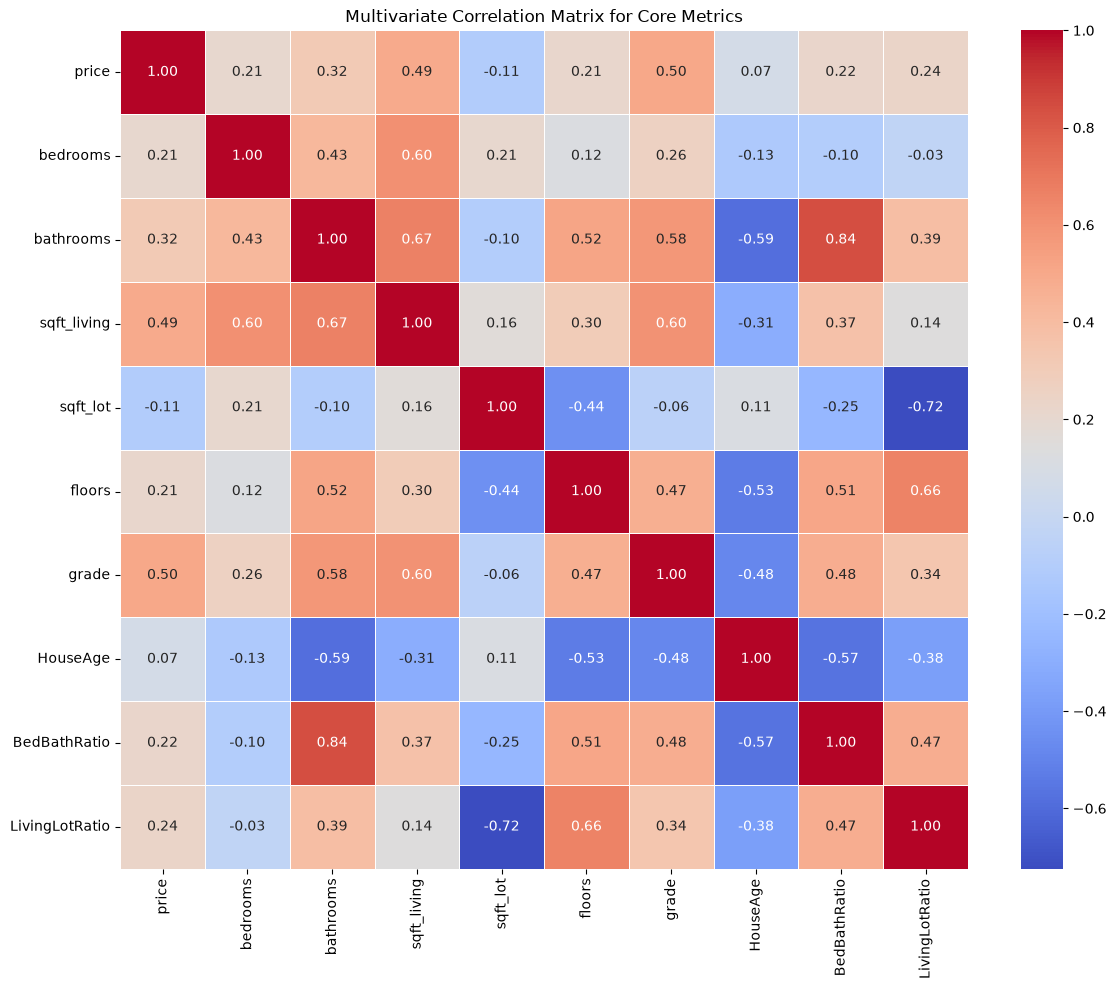

In [22]:
#2c
core_cols = ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 
             'floors', 'grade', 'HouseAge', 'BedBathRatio', 'LivingLotRatio']

plt.figure(figsize=(12, 10))
correlation_matrix = df[core_cols].corr()

# Plot heatmap with correlation scores inside the boxes
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Multivariate Correlation Matrix for Core Metrics')
plt.tight_layout()
plt.show()

> **right-skewed (using `np.log1p`) and left-skewed data (using `PowerTransformer`)**

```python
# --- CASE 1: RIGHT-SKEWED DATA (e.g., Price, Income) ---
from sklearn.preprocessing import PowerTransformer
y_right_transformed = np.log1p(df['price']) #Accepts 1D column vectors.

#Back to real values
y_right_real = np.expm1(y_right_transformed)

#-----------------------------------------------

# --- CASE 2: LEFT-SKEWED DATA (e.g., Year Built, Scores) ---
pt = PowerTransformer(method='yeo-johnson') #Yeo-Johnson handles left-skew perfectly

y_left_reshaped = df[['yr_built']].values
y_left_transformed = pt.fit_transform(y_left_reshaped) #because it works only on 2D

#Back to real values
y_left_real = pt.inverse_transform(y_left_transformed) 
```

Use np.log1p when:
* The data is **right-skewed**:
* All values are **zero or positive**:
* The outliers **are real**, valid data -> The outliers are data entry errors: If a regular house is listed at $80,000,000 due to a typo, delete the row instead.

**Step 7: Define Features (X) and Target (y)**

In [23]:
# Separate features and target
X = df.drop(columns=['price'])

# Log-transform transforms right-skewed data into a normal distribution for ML
# calculates the natural logarithm of 1 + x(each element).
y = np.log1p(df['price']) 

# Group numerical and categorical feature tags for later pipeline mapping
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(include=['str', 'category']).columns.tolist()

**Step 8: Train-Test Split**

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"X_train Shape: {X_train.shape} | X_test Shape: {X_test.shape}")

X_train Shape: (11177, 22) | X_test Shape: (2795, 22)


**Step 9: Preprocessing Pipeline**

In [25]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# Fit and transform the data pools safely (preventing data leakage)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


Feature Selection:

In [26]:
# Initialize VarianceThreshold
selector = VarianceThreshold(threshold=0.01)

# Fit and transform the data
X_train_sele = selector.fit_transform(X_train_processed)
X_test_sele = selector.fit_transform(X_test_processed)

print("Original X Train shape:", X_train_processed.shape)
print("Reduced X Train shape:", X_train_sele.shape)
print("Reduced X Test shape:", X_test_sele.shape)

Original X Train shape: (11177, 25)
Reduced X Train shape: (11177, 20)
Reduced X Test shape: (2795, 20)


**Step 10 & 11: Train Models & Regression Metrics**

In [27]:
print("--- 10 & 11. MODEL TRAINING & REGRESSION METRICS ---")

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=6, random_state=42)
}

model_performance = {}

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    preds_log = model.predict(X_test_processed)
    
    # CRITICAL: Inverse transform predictions back from log space to true dollar values
    y_true_actual = np.expm1(y_test)
    y_pred_actual = np.expm1(preds_log)
    
    r2 = r2_score(y_true_actual, y_pred_actual)
    mae = mean_absolute_error(y_true_actual, y_pred_actual)
    rmse = np.sqrt(mean_squared_error(y_true_actual, y_pred_actual))
    
    model_performance[name] = r2
    print(f"[{name}]     -> R2 Score: {r2*100:.2f}% | MAE: ${mae:,.2f} | RMSE: ${rmse:,.2f}")


--- 10 & 11. MODEL TRAINING & REGRESSION METRICS ---
[Linear Regression]     -> R2 Score: 65.08% | MAE: $79,458.17 | RMSE: $116,276.53
[Decision Tree]     -> R2 Score: 71.17% | MAE: $69,303.75 | RMSE: $105,661.64
[Random Forest]     -> R2 Score: 83.69% | MAE: $50,740.62 | RMSE: $79,479.57
[XGBoost]     -> R2 Score: 86.81% | MAE: $45,452.47 | RMSE: $71,462.68


**Step 12: Cross Validation**

In [28]:
print("--- 12. CROSS VALIDATION ---")

# Let's cross-validate our top baseline performer (XGBoost) using 3-Folds
xgb_cv = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=42)
cv_scores = cross_val_score(xgb_cv, X_train_processed, y_train, cv=3, scoring='r2')

print(f"3-Fold Cross-Validation R2 Scores: {cv_scores}")
print(f"Mean Cross-Validation R2 Accuracy: {cv_scores.mean()*100:.2f}%")


--- 12. CROSS VALIDATION ---
3-Fold Cross-Validation R2 Scores: [0.85159378 0.85615677 0.85736922]
Mean Cross-Validation R2 Accuracy: 85.50%


**Step 13: Feature Selection**

we did before...

**Step 14: Hyperparameter Tuning**

In [29]:
xgb_to_tune = XGBRegressor(random_state=42)

param_distributions = {
    'n_estimators': [150, 170, 190],
    'learning_rate': [0.03, 0.07, 0.1, 0.05],
    'max_depth': [5, 6, 7],
    'subsample': [0.8, 0.9]
}

# Run Randomized Search to find optimal hyperparameter balances quickly
random_search = RandomizedSearchCV(
    estimator=xgb_to_tune, 
    param_distributions=param_distributions, 
    n_iter=3, 
    cv=2, 
    scoring='r2', 
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_processed, y_train)
best_tuned_regressor = random_search.best_estimator_

print("Optimal Hyperparameters Discovered:", random_search.best_params_)
#     "XGBoost": XGBRegressor(n_estimators=150, learning_rate=0.05, max_depth=6, random_state=42)


Optimal Hyperparameters Discovered: {'subsample': 0.8, 'n_estimators': 170, 'max_depth': 6, 'learning_rate': 0.05}


In [30]:
check_regressor = XGBRegressor(
    subsample=0.8,
    n_estimators=170,
    max_depth=6,
    learning_rate=0.05
    #random_state=42  # Keeps results reproducible
)

# 2. Fit the model on your advanced training data
check_regressor.fit(X_train_processed, y_train)

# 3. Evaluate predictions to confirm performance
y_pred = check_regressor.predict(X_test_processed)
print(f"Verification Test R²: {r2_score(y_test, y_pred):.4f}\n")


Verification Test R²: 0.8852



**Step 15: Feature Importance**

In [31]:
importance = pd.DataFrame({
    'Feature': preprocessor.get_feature_names_out(),
    'Importance': best_tuned_regressor.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n--- TOP FEATURE IMPORTANCE SCORES ---")
print(importance.to_string(index=False))



--- TOP FEATURE IMPORTANCE SCORES ---
                     Feature  Importance
                    num__lat    0.339615
            num__sqft_living    0.221717
                  num__grade    0.116885
cat__Condition_Label_Average    0.033456
                   num__long    0.031855
               num__HouseAge    0.031755
          num__sqft_living15    0.030219
             num__sqft_above    0.028473
 cat__Condition_Label_Luxury    0.027628
              num__year_sold    0.021103
   cat__Condition_Label_Fair    0.018165
               num__yr_built    0.016605
              num__bathrooms    0.013797
           num__BedBathRatio    0.010587
             num__sqft_lot15    0.010516
               num__sqft_lot    0.010279
   cat__Condition_Label_Good    0.010128
         num__LivingLotRatio    0.008459
          num__sqft_basement    0.007627
                 num__floors    0.007537
               num__bedrooms    0.003594
             num__waterfront    0.000000
                  

**Step 16: Final Pipeline Production**

In [32]:
# Seamlessly combine our Step 9 Preprocessor and Step 16 Best Tuned Model into ONE unified object
final_production_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', best_tuned_regressor)
])

print("Comprehensive Production Pipeline has been built and trained successfully!")
final_production_pipeline.fit(X_train, y_train)

Comprehensive Production Pipeline has been built and trained successfully!


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['bedrooms','bathrooms','sqft_living',...,'BedBathRatio','LivingLotRatio', 'Condition_Label']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed throu

**Step 17: Save Model & Load Model**

In [33]:
# Save payload dictionary containing both pipeline and column order tracking tags
saved_payload = {
    "model_pipeline": final_production_pipeline,
    "feature_names": X.columns.tolist()
}

# Save model file directly to current working directory
joblib.dump(saved_payload, "xgboost_pipeline.pkl")
print("Model payload successfully saved as 'xgboost_pipeline.pkl'")

Model payload successfully saved as 'xgboost_pipeline.pkl'


In [34]:
# --- Testing the Load Functionality ---
loaded_payload = joblib.load("xgboost_pipeline.pkl")
test_loaded_pipeline = loaded_payload["model_pipeline"]
print("Model loaded back into script successfully! Ready for online server deployment production steps.")

Model loaded back into script successfully! Ready for online server deployment production steps.


1. Understanding the Problem Statement
    * Objective: Predict house values
    * Target definition (price)
    * Feature mapping (Structural, temporal, and spatial columns)
    * Identifying target distribution issues (Handling right-skewness)

2. Data Collection
    * Pandas DataFrame loading (df)

3. Data Checks to perform
    - Shape inspection (df.shape)
    - Variance analysis (df.var())
    - Check Missing values
    - Check Duplicates
    - Check data type
    - Check the number of unique values of each column
    - Check statistics of data set
    - check dataset information

4. Exploratory data analysis
    - Univariate Target & features Analysis
    - Bivariate analysis
    - Multivariate  analysis
    - Multivariate Core Correlation

5. Data Pre-Processing
    - Outlier removal (IQR method)
    - Target transformation (np.log1p)
    - Feature transformation (PowerTransformer, FunctionTransformer)
    - Missing values (SimpleImputer)
    - Scaling (StandardScaler)
    - Encoding (OneHotEncoder)
    - Data splitting (train_test_split)
    - Pipeline automation (Pipeline, ColumnTransformer)

6. Model Training
    - LinearRegression
    - DecisionTreeRegressor
    - RandomForestRegressor
    - XGBRegressor

7. Choose best model
    - Inverse prediction transform (np.expm1)
    - Performance evaluation (r2_score, mean_absolute_error, mean_squared_error)

For Numerical Columns
* sns.histplot(kde=True) 
    - Best for spotting `data skewness` (long right or left tails).
* sns.boxplot()
    - Best for instantly `spotting extreme outliers` (dots outside the whiskers).

For Categorical Columns 
* sns.countplot()
    - Best for `comparing the total frequencies` of different category labels.
    - Best for instantly spotting imbalanced classes